In [2]:
%pip install sympy scipy

   ---------------------------------------- 0.0/6.3 MB ? eta -:--:--
   ----------- ---------------------------- 1.8/6.3 MB 11.1 MB/s eta 0:00:01
   --------------------- ------------------ 3.4/6.3 MB 8.9 MB/s eta 0:00:01
   -------------------------- ------------- 4.2/6.3 MB 7.1 MB/s eta 0:00:01
   ------------------------------------ --- 5.8/6.3 MB 7.0 MB/s eta 0:00:01
   -------------------------------------- - 6.0/6.3 MB 7.0 MB/s eta 0:00:01
   -------------------------------------- - 6.0/6.3 MB 7.0 MB/s eta 0:00:01
   -------------------------------------- - 6.0/6.3 MB 7.0 MB/s eta 0:00:01
   -------------------------------------- - 6.0/6.3 MB 7.0 MB/s eta 0:00:01
   ---------------------------------------- 6.3/6.3 MB 3.3 MB/s  0:00:01
   ---------------------------------------- 0.0/536.2 kB ? eta -:--:--
   ------------------- -------------------- 262.1/536.2 kB ? eta -:--:--
   ---------------------------------------- 536.2/536.2 kB 898.7 kB/s  0:00:00
   -----------------------

NORMALIZED ENERGY EIGENFUNCTIONS

elliptic coordinates:  x = c cosh(xi) cos(eta),  y = c sinh(xi) sin(eta)
boundary:              xi = xi0,  tanh(xi0) = b/a,  c = sqrt(a^2 - b^2)

psi_C(m,j)(xi,eta) = N Ce_m(xi; q) ce_m(eta; q)      (m = 0, 1, 2, ...)
psi_S(m,j)(xi,eta) = N Se_m(xi; q) se_m(eta; q)      (m = 1, 2, 3, ...)

separated equations:  R'' = (A - 2 q cosh(2 xi)) R,   P'' = -(A - 2 q cos(2 eta)) P
with
     2  2
    c *k 
q = -----
      4  

scale factor  h^2 = |dr/dxi|^2 = |dr/deta|^2 =
 2 /   2            2    \
c *\sin (eta) + sinh (xi)/

area element:  dA = h^2 dxi deta

quantization:  Ce_m(xi0; q) = 0   (psi_C)     Se_m(xi0; q) = 0   (psi_S)
               q(m,j) = j-th root (j = 1, 2, ...), one root per radial node

N^(-2) =
 xi0 2*pi                                                       
  /    /                                                        
 |    |                                                         
 |    |   2 /   2            2    \               2    

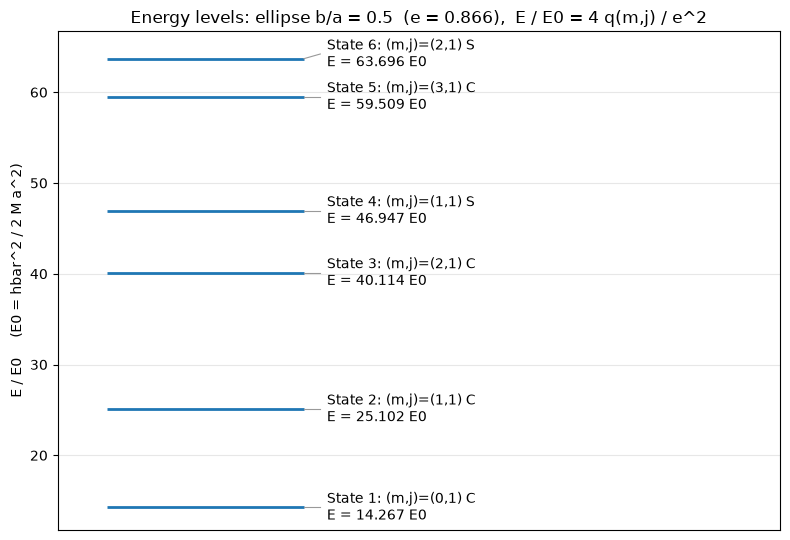

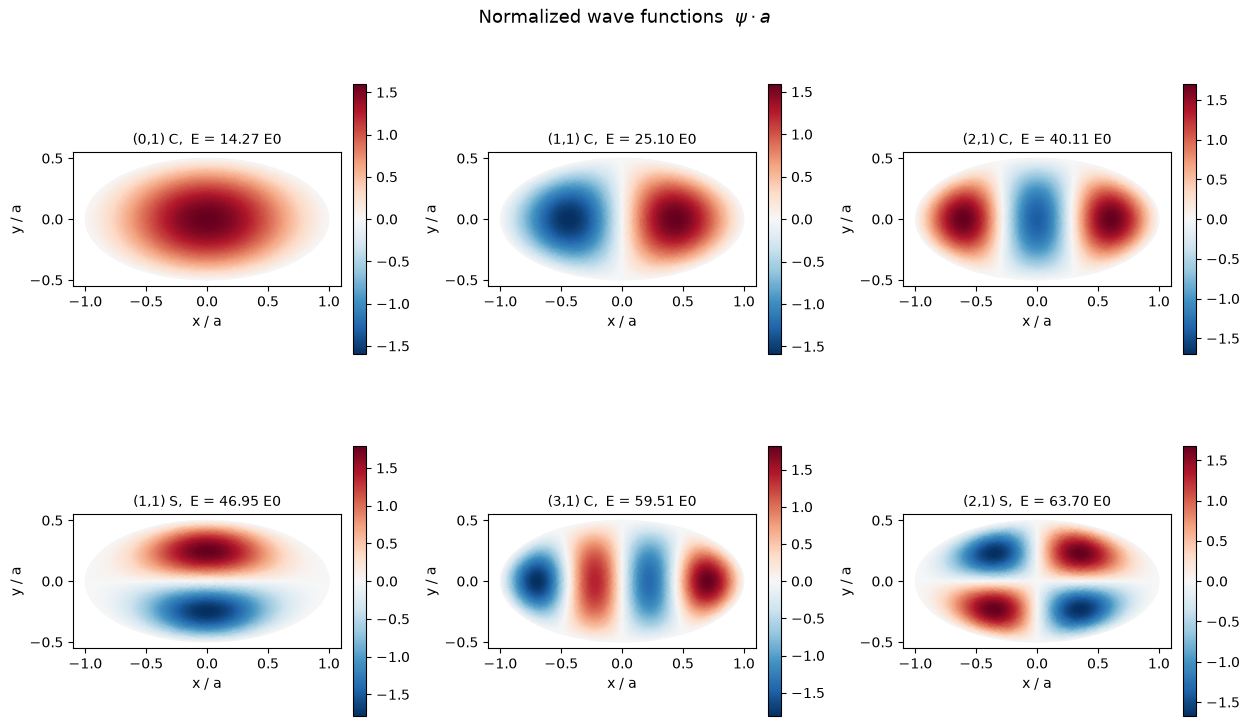

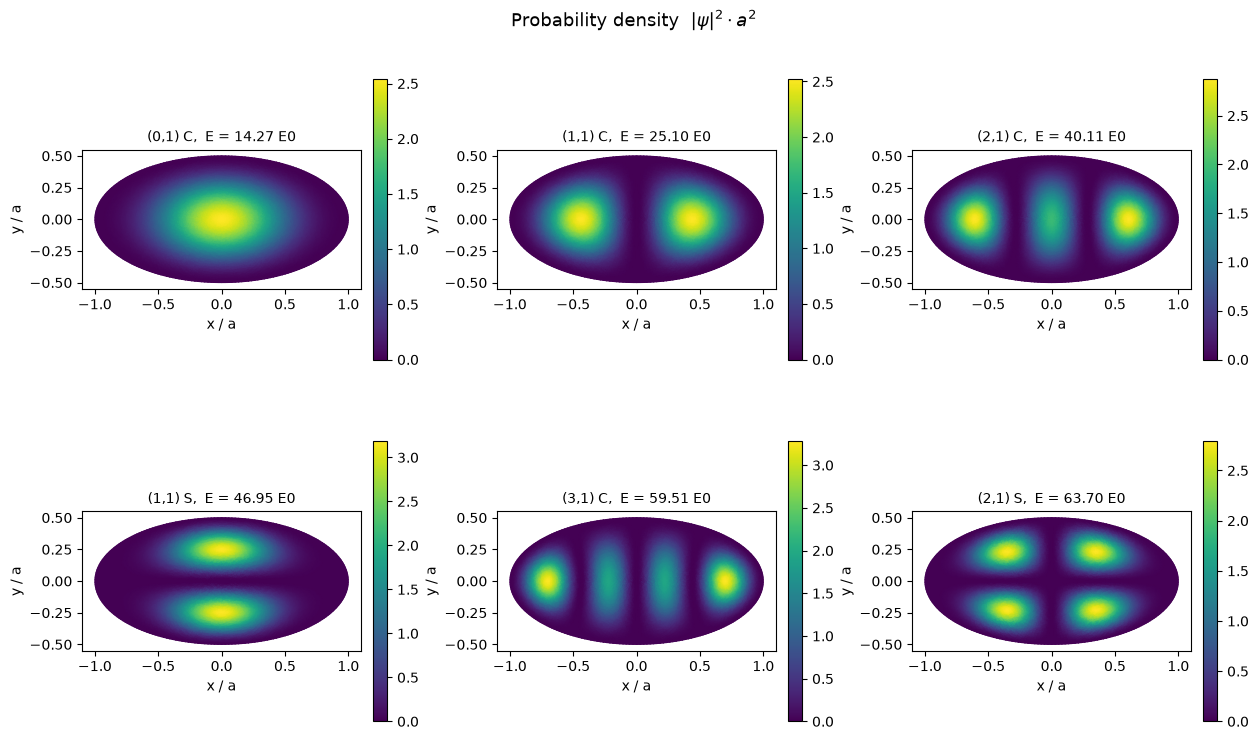

In [1]:
"""Particle (electron) in an elliptical infinite well.

Same layout as triangular_well_eigen.py:
  1. sympy derivation / checks, printed as normalized eigenfunctions + energy formula
  2. energy-level diagram
  3. grid of wave functions  psi * a
  4. grid of probability densities  |psi|^2 * a^2

Set the ellipse with SEMI_MAJOR (a) and SEMI_MINOR (b) below, any units, with
0 < b < a.  Only the ratio b/a changes the shape; a is the unit of length
(plots are in x/a, y/a) and sets the energy unit E0 = hbar^2 / (2 M a^2),
so that E / E0 = (k a)^2.  Focal distance c = e a with e = sqrt(1 - (b/a)^2).

Unlike the triangle, the ellipse has no closed-form spectrum: the separated
solutions are Mathieu functions and the energies are roots of
Ce_m(xi0; q) = 0  (psi_C)   or   Se_m(xi0; q) = 0  (psi_S).
"""
import argparse
import os
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from scipy.integrate import solve_ivp
from scipy.linalg import eigh_tridiagonal, eigvalsh_tridiagonal
from scipy.optimize import brentq

NUM_STATES = 6
GRID = 80             # radial resolution of the plotting mesh

SEMI_MAJOR = 2.0      # a   <-- set to your ellipse (x semi-axis, the longer one)
SEMI_MINOR = 1.0      # b   <-- set to your ellipse (y semi-axis)
if not 0 < SEMI_MINOR < SEMI_MAJOR:
    raise ValueError("need 0 < SEMI_MINOR < SEMI_MAJOR (b = a is a circle: no foci, "
                     "use Bessel functions; for b > a swap x and y)")
B_OVER_A = SEMI_MINOR / SEMI_MAJOR      # b / a

ECC = np.sqrt(1.0 - B_OVER_A ** 2)      # e = c / a
C_FOC = ECC                             # focal distance c  (a = 1)
XI0 = np.arctanh(B_OVER_A)              # boundary: a = c cosh(xi0), b = c sinh(xi0)
K_STEP = 0.02                           # step in k*a for the root search

# ---------------------------------------------------------------- symbolic part
xi, eta, c, q, A = sp.symbols("xi eta c q A", real=True)
R = sp.Function("R")
P = sp.Function("P")


def show(label, expr):
    print(label)
    print(sp.pretty(expr, use_unicode=False))
    print()


def solve_schrodinger():
    """Separate -hbar^2/2M (psi_xx + psi_yy) = E psi in elliptic coordinates and check it."""
    X = c * sp.cosh(xi) * sp.cos(eta)
    Y = c * sp.sinh(xi) * sp.sin(eta)

    # scale factor h^2 = |dr/dxi|^2 = |dr/deta|^2 and orthogonality of the coordinates
    h2_xi = sp.diff(X, xi) ** 2 + sp.diff(Y, xi) ** 2
    h2_eta = sp.diff(X, eta) ** 2 + sp.diff(Y, eta) ** 2
    h2 = c ** 2 * (sp.sinh(xi) ** 2 + sp.sin(eta) ** 2)
    ortho = sp.diff(X, xi) * sp.diff(X, eta) + sp.diff(Y, xi) * sp.diff(Y, eta)
    pt = {xi: 0.37, eta: 1.21, c: 0.8}
    assert abs(float((h2_xi - h2).subs(pt))) < 1e-12
    assert abs(float((h2_eta - h2).subs(pt))) < 1e-12
    assert abs(float(ortho.subs(pt))) < 1e-12

    # Laplacian in elliptic coordinates, tested on f = x^3 y + y^2  (lap f = 6 x y + 2)
    f = X ** 3 * Y + Y ** 2
    lap = (sp.diff(f, xi, 2) + sp.diff(f, eta, 2)) / h2
    assert abs(float((lap - (6 * X * Y + 2)).subs(pt))) < 1e-10

    # separation psi = R(xi) P(eta):  R'' = (A - 2q cosh 2xi) R,  P'' = -(A - 2q cos 2eta) P
    psi_sym = R(xi) * P(eta)
    lap_psi = (sp.diff(psi_sym, xi, 2) + sp.diff(psi_sym, eta, 2)) / h2
    lap_psi = lap_psi.subs({sp.Derivative(R(xi), (xi, 2)): (A - 2 * q * sp.cosh(2 * xi)) * R(xi),
                            sp.Derivative(P(eta), (eta, 2)): -(A - 2 * q * sp.cos(2 * eta)) * P(eta)})
    k2 = 4 * q / c ** 2
    residual = lap_psi + k2 * psi_sym
    assert abs(float(residual.subs({**pt, q: 1.3, A: 0.7, R(xi): 1.9, P(eta): -0.4}))) < 1e-10
    return h2, k2


def print_results():
    h2, k2 = solve_schrodinger()
    hbar, M, a, E = sp.symbols("hbar M a E", positive=True)
    m, j = sp.symbols("m j", positive=True, integer=True)
    print("NORMALIZED ENERGY EIGENFUNCTIONS")
    print()
    print("elliptic coordinates:  x = c cosh(xi) cos(eta),  y = c sinh(xi) sin(eta)")
    print("boundary:              xi = xi0,  tanh(xi0) = b/a,  c = sqrt(a^2 - b^2)")
    print()
    print("psi_C(m,j)(xi,eta) = N Ce_m(xi; q) ce_m(eta; q)      (m = 0, 1, 2, ...)")
    print("psi_S(m,j)(xi,eta) = N Se_m(xi; q) se_m(eta; q)      (m = 1, 2, 3, ...)")
    print()
    print("separated equations:  R'' = (A - 2 q cosh(2 xi)) R,   P'' = -(A - 2 q cos(2 eta)) P")
    show("with", sp.Eq(q, sp.Symbol("k") ** 2 * c ** 2 / 4))
    show("scale factor  h^2 = |dr/dxi|^2 = |dr/deta|^2 =", h2)
    print("area element:  dA = h^2 dxi deta")
    print()
    print("quantization:  Ce_m(xi0; q) = 0   (psi_C)     Se_m(xi0; q) = 0   (psi_S)")
    print("               q(m,j) = j-th root (j = 1, 2, ...), one root per radial node")
    print()
    psi_f = sp.Function("psi")(xi, eta)
    show("N^(-2) =", sp.Integral(sp.Abs(psi_f) ** 2 * h2, (eta, 0, 2 * sp.pi), (xi, 0, sp.Symbol("xi0"))))
    print("             = c^2 [ int R^2 sinh^2(xi) dxi * int P^2 deta + int R^2 dxi * int P^2 sin^2(eta) deta ]")
    print("               (done numerically, with R, P = Mathieu functions)")
    print()
    print("ENERGY EIGENVALUE")
    print()
    show("E(m,j) = hbar^2 k^2 / 2M =", sp.Eq(E, hbar ** 2 * 4 * q / (2 * M * c ** 2)))
    E0 = hbar ** 2 / (2 * M * a ** 2)
    show("E(m,j) = E0 * 4 q(m,j) / e^2 = E0 (k a)^2,  e = c/a,  where E0 =", E0)


# -------------------------------------------------------------- Mathieu functions
# Angular equation   P'' + (A - 2 q cos 2 eta) P = 0     -> ce_m, se_m  (Fourier series)
# Radial equation    R'' - (A - 2 q cosh 2 xi) R = 0     -> Ce_m, Se_m
#   ce_m = sum c_n cos(n eta),  se_m = sum c_n sin(n eta)  with (c_n, A) from a symmetric
#   tridiagonal eigenproblem built here directly (no special-function library).
#   Ce_m is the solution with R(0)=1, R'(0)=0 ; Se_m the one with R(0)=0, R'(0)=1
#   (these are proportional to the usual modified Mathieu functions, which is all the
#   quantization condition and the normalised wave function need).
def _harmonics(kind, m, K):
    start = 1 if m % 2 else (0 if kind == "C" else 2)
    return start + 2 * np.arange(K)


def _tridiag(kind, m, qq, K):
    n = _harmonics(kind, m, K)
    d = n.astype(float) ** 2
    e = np.full(K - 1, qq)
    if m % 2:                                   # odd harmonics: first diagonal gets +/- q
        d[0] += qq if kind == "C" else -qq
    elif kind == "C":                           # n = 0 row couples with weight sqrt(2) q
        e[0] = np.sqrt(2.0) * qq
    r = (m - 1) // 2 if m % 2 else (m // 2 if kind == "C" else m // 2 - 1)
    return n, d, e, r


def _size(qq):
    return int(14 + 6 * np.sqrt(abs(qq)))


def char_value(kind, m, qq):
    """Characteristic value A (a_m or b_m) of the angular equation."""
    n, d, e, r = _tridiag(kind, m, qq, _size(qq))
    return eigvalsh_tridiagonal(d, e, select="i", select_range=(r, r))[0]


_cache = {}


def fourier(kind, m, qq):
    key = ("F", kind, m, round(float(qq), 13))
    if key not in _cache:
        K = _size(qq)
        while True:
            n, d, e, r = _tridiag(kind, m, qq, K)
            w, v = eigh_tridiagonal(d, e, select="i", select_range=(r, r))
            c = v[:, 0].copy()
            if kind == "C" and m % 2 == 0:
                c[0] /= np.sqrt(2.0)            # undo the symmetrising rescale of A_0
            if abs(c[-1]) < 1e-14 or K > 400:
                break
            K = int(K * 1.5)
        _cache[key] = (n, c)
    return _cache[key]


def angular(kind, m, qq, eta_):
    n, c = fourier(kind, m, qq)
    f = np.cos if kind == "C" else np.sin
    return f(np.multiply.outer(np.asarray(eta_, float), n)) @ c


def _solve_radial(kind, m, qq, dense):
    A = char_value(kind, m, qq)
    y0 = [1.0, 0.0] if kind == "C" else [0.0, 1.0]
    return solve_ivp(lambda x, y: [y[1], (A - 2 * qq * np.cosh(2 * x)) * y[0]],
                     (0.0, XI0), y0, method="DOP853", rtol=1e-13, atol=1e-16,
                     dense_output=dense)


def radial(kind, m, qq, xi_):
    key = ("R", kind, m, round(float(qq), 13))
    if key not in _cache:
        _cache[key] = _solve_radial(kind, m, qq, True).sol
    xi_ = np.asarray(xi_, float)
    return _cache[key](xi_.ravel())[0].reshape(xi_.shape)


def _scan_radial(kind, m, qs):
    """R(xi0; q) for an array of q at once (fixed-step RK4), only used to bracket roots."""
    A = np.array([char_value(kind, m, t) for t in qs])
    lam = np.max(np.abs(A) + 2 * qs * np.cosh(2 * XI0))
    N = int(np.clip(XI0 * np.sqrt(lam) * 40, 200, 8000))
    h = XI0 / N
    R = np.ones_like(qs) if kind == "C" else np.zeros_like(qs)
    D = np.zeros_like(qs) if kind == "C" else np.ones_like(qs)

    def acc(x, r):
        return (A - 2 * qs * np.cosh(2 * x)) * r

    x = 0.0
    for _ in range(N):
        k1r, k1d = D, acc(x, R)
        k2r, k2d = D + 0.5 * h * k1d, acc(x + 0.5 * h, R + 0.5 * h * k1r)
        k3r, k3d = D + 0.5 * h * k2d, acc(x + 0.5 * h, R + 0.5 * h * k2r)
        k4r, k4d = D + h * k3d, acc(x + h, R + h * k3r)
        R = R + h / 6 * (k1r + 2 * k2r + 2 * k3r + k4r)
        D = D + h / 6 * (k1d + 2 * k2d + 2 * k3d + k4d)
        x += h
    return R


def roots_for(kind, m, kmax):
    """All q with Ce_m(xi0;q)=0 (kind C) or Se_m(xi0;q)=0 (kind S) for k*a < kmax.

    Scanned in the wave number k (q = k^2 c^2 / 4): consecutive roots are always
    well separated in k, so a fixed step cannot skip a pair of roots.
    """
    ks = np.arange(K_STEP, kmax + K_STEP, K_STEP)
    qs = ks ** 2 * C_FOC ** 2 / 4
    vals = _scan_radial(kind, m, qs)
    out = []
    for i in np.nonzero(vals[:-1] * vals[1:] < 0)[0]:
        out.append(brentq(lambda t: _solve_radial(kind, m, t, False).y[0, -1],
                          qs[i], qs[i + 1], xtol=1e-14, rtol=1e-14))
    return out


def lowest_states(count):
    """The `count` lowest states as (E/E0, m, j, kind, q), sorted by energy."""
    kmax = 6.0
    while True:
        found = []
        m = 0
        while True:
            n_new = 0
            for kind in "CS":
                if kind == "S" and m == 0:
                    continue
                for jj, qq in enumerate(roots_for(kind, m, kmax), 1):
                    found.append((4 * qq / ECC ** 2, m, jj, kind, qq))
                    n_new += 1
            if n_new == 0 and m >= 1:
                break
            m += 1
        if len(found) >= count:
            found.sort()
            return found[:count]
        kmax *= 1.4


# ------------------------------------------------------------------ eigenfunctions
_gl_x, _gl_w = np.polynomial.legendre.leggauss(200)
XI_NODES = 0.5 * XI0 * (_gl_x + 1)
XI_W = 0.5 * XI0 * _gl_w
ETA_NODES = np.linspace(0, 2 * np.pi, 4096, endpoint=False)
ETA_W = 2 * np.pi / ETA_NODES.size

_norm_cache = {}


def norm_const(m, kind, qq):
    key = (m, kind, round(qq, 12))
    if key not in _norm_cache:
        Rv = radial(kind, m, qq, XI_NODES)
        Pv = angular(kind, m, qq, ETA_NODES)
        I1 = np.sum(XI_W * Rv ** 2 * np.sinh(XI_NODES) ** 2)
        I2 = np.sum(XI_W * Rv ** 2)
        J1 = ETA_W * np.sum(Pv ** 2)
        J2 = ETA_W * np.sum(Pv ** 2 * np.sin(ETA_NODES) ** 2)
        _norm_cache[key] = 1.0 / np.sqrt(C_FOC ** 2 * (I1 * J1 + I2 * J2))
    return _norm_cache[key]


def to_elliptic(x, y):
    w = np.arccosh((np.asarray(x) + 1j * np.asarray(y)) / C_FOC + 0j)
    return w.real, w.imag                       # xi >= 0, eta in (-pi, pi]


def psi(m, kind, qq, x, y):
    xi_, eta_ = to_elliptic(x, y)
    return norm_const(m, kind, qq) * radial(kind, m, qq, xi_) * angular(kind, m, qq, eta_)


def verify(states):
    """Boundary condition, Schroedinger equation and orthonormality checks."""
    print("CHECKS")
    th = np.linspace(0, 2 * np.pi, 721)
    rng = np.random.default_rng(1)
    r = np.sqrt(rng.uniform(0.05, 0.9, 40))
    t = rng.uniform(0, 2 * np.pi, 40)
    xs, ys = r * np.cos(t), r * B_OVER_A * np.sin(t)
    h = 1e-3
    Smat = np.zeros((len(states), len(states)))
    wave = []
    for (E, m, jj, kind, qq) in states:
        f = lambda X, Y: psi(m, kind, qq, X, Y)
        edge = np.max(np.abs(f(np.cos(th), B_OVER_A * np.sin(th))))
        lap = (f(xs + h, ys) + f(xs - h, ys) + f(xs, ys + h) + f(xs, ys - h) - 4 * f(xs, ys)) / h ** 2
        resid = np.max(np.abs(lap + E * f(xs, ys)))
        print(f"  ({m},{jj}) {kind}:  max|psi| on boundary = {edge:.1e},   "
              f"max|lap psi + (E/E0) psi| = {resid:.1e}")
        assert edge < 1e-6 and resid < 1e-3 * max(1.0, E)
        xg, eg = np.meshgrid(XI_NODES, ETA_NODES, indexing="ij")
        Rv = radial(kind, m, qq, XI_NODES)[:, None]
        Pv = angular(kind, m, qq, ETA_NODES)[None, :]
        wave.append(norm_const(m, kind, qq) * Rv * Pv)
    area = C_FOC ** 2 * (np.sinh(XI_NODES)[:, None] ** 2 + np.sin(ETA_NODES)[None, :] ** 2)
    for a_ in range(len(states)):
        for b_ in range(len(states)):
            Smat[a_, b_] = np.sum(XI_W[:, None] * ETA_W * wave[a_] * wave[b_] * area)
    err = np.max(np.abs(Smat - np.eye(len(states))))
    print(f"  max |<psi_i|psi_j> - delta_ij| = {err:.1e}")
    assert err < 1e-8
    print()


# ----------------------------------------------------------------------- plotting
def ellipse_mesh(N):
    nt = 3 * N
    rho = np.arange(1, N + 1) / N
    th = 2 * np.pi * np.arange(nt) / nt
    px = np.concatenate([[0.0], (rho[:, None] * np.cos(th)[None, :]).ravel()])
    py = np.concatenate([[0.0], (B_OVER_A * rho[:, None] * np.sin(th)[None, :]).ravel()])
    return mtri.Triangulation(px, py)


def plot_energy_levels(states):
    groups = []
    for i, (v, m, jj, kind, qq) in enumerate(states, 1):
        if groups and abs(groups[-1][0] - v) < 1e-6 * v:
            groups[-1][1].append((i, m, jj, kind))
        else:
            groups.append([v, [(i, m, jj, kind)]])
    plt.figure(figsize=(8, 5.5))
    gap = 0.085 * (groups[-1][0] - groups[0][0] + 1e-9) + 0.5   # keep neighbouring labels apart
    label_y = []
    for v, mem in groups:
        label_y.append(max(v, label_y[-1] + gap) if label_y else v)
    for (v, mem), ly in zip(groups, label_y):
        plt.hlines(v, 0.15, 0.75, linewidth=2)
        plt.plot([0.75, 0.80], [v, ly], color="0.6", linewidth=0.8)
        names = ", ".join(str(a[0]) for a in mem)
        tag = "State" if len(mem) == 1 else f"States ({len(mem)}-fold)"
        mj = f"(m,j)=({mem[0][1]},{mem[0][2]}) {mem[0][3]}"
        plt.text(0.82, ly, f"{tag} {names}: {mj}\nE = {v:.3f} E0", va="center")
    plt.xlim(0, 2.2)
    plt.xticks([])
    plt.ylabel("E / E0     (E0 = hbar^2 / 2 M a^2)")
    plt.title(f"Energy levels: ellipse b/a = {B_OVER_A:g}  (e = {ECC:.3g}),  E / E0 = 4 q(m,j) / e^2")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()


def fields_on_mesh(states, tri):
    out = []
    for (v, m, jj, kind, qq) in states:
        f = psi(m, kind, qq, tri.x, tri.y)
        if f[np.argmax(np.abs(f))] < 0:
            f = -f
        out.append(f)
    return out


def plot_grid(states, tri, fields, what):
    cols = 3
    rows = int(np.ceil(len(states) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 3.9 * rows),
                             squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (v, m, jj, kind, qq), f in zip(axes.ravel(), states, fields):
        ax.axis("on")
        if what == "psi":
            vmax = np.max(np.abs(f))
            art = ax.tripcolor(tri, f, shading="gouraud", cmap="RdBu_r",
                               vmin=-vmax, vmax=vmax, rasterized=True)
        else:
            art = ax.tripcolor(tri, f ** 2, shading="gouraud", cmap="viridis", rasterized=True)
        ax.set_title(f"({m},{jj}) {kind},  E = {v:.2f} E0", fontsize=10)
        ax.set_aspect("equal")
        ax.set_xlabel("x / a")
        ax.set_ylabel("y / a")
        fig.colorbar(art, ax=ax, fraction=0.046, pad=0.04)
    if what == "psi":
        fig.suptitle(r"Normalized wave functions  $\psi \cdot a$", fontsize=13)
    else:
        fig.suptitle(r"Probability density  $|\psi|^2 \cdot a^2$", fontsize=13)
    fig.tight_layout()
    return fig


def print_table(states):
    print("COMPUTED STATES  (a = %g, b = %g, b/a = %g, e = %.4g, xi0 = %.6f, c/a = %.4g)" %
          (SEMI_MAJOR, SEMI_MINOR, B_OVER_A, ECC, XI0, C_FOC))
    print()
    print("  #   (m,j)  type    q(m,j)       E / E0")
    for i, (v, m, jj, kind, qq) in enumerate(states, 1):
        print(f"  {i:<3d} ({m},{jj})   {kind}    {qq:10.6f}   {v:10.5f}")
    print()


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--save", metavar="DIR", help="save the three figures as PDF in DIR instead of showing them")
    args, _ = ap.parse_known_args()      # ignores Jupyter's own arguments
    if args.save:
        import matplotlib
        matplotlib.use("Agg")

    print_results()
    states = lowest_states(NUM_STATES)
    print_table(states)
    verify(states)
    tri = ellipse_mesh(GRID)
    fields = fields_on_mesh(states, tri)
    plot_energy_levels(states)
    fig_e = plt.gcf()
    fig_psi = plot_grid(states, tri, fields, "psi")
    fig_rho = plot_grid(states, tri, fields, "rho")
    if args.save:
        os.makedirs(args.save, exist_ok=True)
        for name, fig in (("ellipse_levels", fig_e), ("ellipse_psi", fig_psi), ("ellipse_rho", fig_rho)):
            fig.savefig(f"{args.save}/{name}.pdf")
    else:
        plt.show()


if __name__ == "__main__":
    main()